# 10. Model Error Analysis — NEU-DET

This notebook investigates **why** the current detector misses defects and produces false positives.

- Uses the **validation split only**.
- Does not train, fine-tune, or modify model weights.
- Does not use the test split.
- Uses the same MobileNetV2 preprocessing, model output layout, decoder, confidence threshold, and NMS setting used in the corrected evaluation notebooks.

Run this after Notebooks 07 and 08. The goal is to collect evidence before changing the architecture or loss function.

In [1]:

import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found. Open from project root or notebooks folder.")
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
BASELINE_PATH = PROJECT_ROOT / "models" / "best_model.keras"
FOCAL_PATH = PROJECT_ROOT / "models" / "focal_experiment" / "best_model_focal.keras"
ANCHORS_PATH = PROJECT_ROOT / "models" / "anchors.npy"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["crazing", "inclusion", "patches",
               "pitted_surface", "rolled-in_scale", "scratches"]
NUM_CLASSES, GRID_SIZE, NUM_ANCHORS, IMAGE_SIZE = 6, 7, 5, 224
print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)



Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.15.0


## 1. Load the selected model and validation data

In [2]:

from src.data.dataset import get_dataset_splits

train_samples, val_samples, test_samples = get_dataset_splits(str(DATASET_PATH))
print("Train:",len(train_samples),"Validation:",len(val_samples),"Test:",len(test_samples))
print("This notebook will use validation samples only.")

# Choose the model whose error patterns you want to inspect.
MODEL_NAME = "Focal_Loss"
MODEL_PATH = FOCAL_PATH if MODEL_NAME == "Focal_Loss" else BASELINE_PATH
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Missing checkpoint: {MODEL_PATH}")

settings_path = RESULTS_DIR / f"{MODEL_NAME.lower()}_selected_validation_settings.json"
if not settings_path.exists():
    raise FileNotFoundError(f"Missing validation settings file: {settings_path}")

with open(settings_path,"r",encoding="utf-8") as f:
    settings=json.load(f)
CONF_THRESHOLD=float(settings["confidence_threshold"])
NMS_IOU=float(settings["nms_iou_threshold"])
MATCH_IOU=float(settings.get("matching_iou_threshold",0.5))

model=tf.keras.models.load_model(MODEL_PATH,compile=False)
anchors=np.load(ANCHORS_PATH).astype(np.float32)
assert anchors.shape==(NUM_ANCHORS,2), anchors.shape
print("Model:",MODEL_NAME)
print("Output shape:",model.output_shape)
print("Settings:",settings)
print("Anchors:\n",anchors)


Train: 1151 Validation: 288 Test: 360
This notebook will use validation samples only.


Model: Focal_Loss
Output shape: (None, 7, 7, 5, 11)
Settings: {'model': 'Focal_Loss', 'confidence_threshold': 0.6, 'nms_iou_threshold': 0.5, 'matching_iou_threshold': 0.5, 'data_split': 'validation', 'warning': 'Do not use these settings as final test results until frozen.'}
Anchors:
 [[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 2. Preprocessing and decoding (must match training/evaluation)

In [3]:

def load_image(image_path):
    image=Image.open(image_path).convert("RGB").resize((IMAGE_SIZE,IMAGE_SIZE))
    image=np.asarray(image,dtype=np.float32)
    image=tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image.astype(np.float32)

def box_iou_xyxy(a,b):
    ax1,ay1,ax2,ay2=map(float,a); bx1,by1,bx2,by2=map(float,b)
    ix1,iy1=max(ax1,bx1),max(ay1,by1)
    ix2,iy2=min(ax2,bx2),min(ay2,by2)
    inter=max(0,ix2-ix1)*max(0,iy2-iy1)
    area_a=max(0,ax2-ax1)*max(0,ay2-ay1)
    area_b=max(0,bx2-bx1)*max(0,by2-by1)
    return inter/(area_a+area_b-inter+1e-9)

def get_gt(sample):
    return (np.asarray(sample["boxes"],dtype=np.float32).reshape(-1,4),
            np.asarray(sample["labels"],dtype=np.int32).reshape(-1))

def decode_predictions(raw, conf_threshold=CONF_THRESHOLD, nms_iou=NMS_IOU, max_detections=100):
    raw=np.asarray(raw)
    if raw.ndim==5: raw=raw[0]
    expected=(GRID_SIZE,GRID_SIZE,NUM_ANCHORS,5+NUM_CLASSES)
    if raw.shape!=expected:
        raise ValueError(f"Expected {expected}, received {raw.shape}")
    candidates=[]
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            for a in range(NUM_ANCHORS):
                p=raw[row,col,a]
                tx,ty,tw,th=p[:4]
                obj=1/(1+np.exp(-np.clip(float(p[4]),-30,30)))
                logits=p[5:]
                ex=np.exp(logits-np.max(logits))
                probs=ex/(np.sum(ex)+1e-9)
                cls=int(np.argmax(probs)); score=float(obj*probs[cls])
                if score<conf_threshold: continue
                # Encoder stores direct cell offsets, not sigmoid offsets.
                cx=(col+float(np.clip(tx,0,1)))/GRID_SIZE
                cy=(row+float(np.clip(ty,0,1)))/GRID_SIZE
                w=float(anchors[a,0]*np.exp(np.clip(tw,-5,5)))
                h=float(anchors[a,1]*np.exp(np.clip(th,-5,5)))
                box=[float(np.clip(cx-w/2,0,1)),float(np.clip(cy-h/2,0,1)),
                     float(np.clip(cx+w/2,0,1)),float(np.clip(cy+h/2,0,1))]
                if box[2]>box[0] and box[3]>box[1]:
                    candidates.append({"box":box,"score":score,"class_id":cls})
    kept=[]
    for cls in range(NUM_CLASSES):
        pending=sorted([d for d in candidates if d["class_id"]==cls],
                       key=lambda d:d["score"],reverse=True)
        while pending:
            best=pending.pop(0); kept.append(best)
            pending=[d for d in pending if box_iou_xyxy(best["box"],d["box"])<nms_iou]
    return sorted(kept,key=lambda d:d["score"],reverse=True)[:max_detections]

def predict_one(sample):
    x=load_image(sample["image"])[None,...]
    raw=model.predict(x,verbose=0)
    return raw,decode_predictions(raw)


## 3. Run predictions on validation set

In [4]:

validation_predictions=[]
raw_prediction_stats=[]
for i,sample in enumerate(val_samples):
    raw,dets=predict_one(sample)
    raw0=raw[0]
    obj=1/(1+np.exp(-np.clip(raw0[...,4],-30,30)))
    logits=raw0[...,5:]
    ex=np.exp(logits-np.max(logits,axis=-1,keepdims=True))
    probs=ex/(np.sum(ex,axis=-1,keepdims=True)+1e-9)
    combined=obj*np.max(probs,axis=-1)
    validation_predictions.append(dets)
    raw_prediction_stats.append({
        "image_index":i,
        "image":str(sample["image"]),
        "raw_max_objectness":float(obj.max()),
        "raw_mean_objectness":float(obj.mean()),
        "raw_max_combined_score":float(combined.max()),
        "detections_after_nms":len(dets)
    })
    if (i+1)%50==0 or i+1==len(val_samples):
        print(f"{i+1}/{len(val_samples)}")
raw_stats_df=pd.DataFrame(raw_prediction_stats)
display(raw_stats_df.describe().round(4))


50/288
100/288
150/288
200/288
250/288
288/288


,image_index,raw_max_objectness,raw_mean_objectness,raw_max_combined_score,detections_after_nms
count,288.0000,288.0000,288.0000,288.0000,288.0000
mean,143.5000,0.7114,0.1472,0.7062,3.2917
std,83.2827,0.0826,0.0350,0.0867,3.1243
min,0.0000,0.4628,0.0670,0.3462,0.0000
25%,71.7500,0.6600,0.1229,0.6512,1.0000
50%,143.5000,0.7104,0.1473,0.7072,2.0000
75%,215.2500,0.7698,0.1721,0.7656,5.0000
max,287.0000,0.8989,0.2370,0.8986,22.0000


## 4. Match predictions to ground truth and categorize errors

In [5]:

records=[]
for image_idx,(sample,dets) in enumerate(zip(val_samples,validation_predictions)):
    gt_boxes,gt_labels=get_gt(sample)
    used=set()
    for det in sorted(dets,key=lambda x:x["score"],reverse=True):
        same_class=[
            (j,box_iou_xyxy(det["box"],gt_boxes[j]))
            for j in range(len(gt_boxes))
            if j not in used and int(gt_labels[j])==int(det["class_id"])
        ]
        best=max(same_class,key=lambda x:x[1],default=(-1,0.0))
        if best[0]>=0 and best[1]>=MATCH_IOU:
            used.add(best[0])
            status="TP"
            best_iou=best[1]
        else:
            status="FP"
            best_iou=best[1] if best[0]>=0 else 0.0
        records.append({
            "image_index":image_idx,"image":str(sample["image"]),
            "status":status,"predicted_class":CLASS_NAMES[int(det["class_id"])],
            "predicted_class_id":int(det["class_id"]),
            "score":float(det["score"]),"best_same_class_iou":float(best_iou),
            "pred_xmin":det["box"][0],"pred_ymin":det["box"][1],
            "pred_xmax":det["box"][2],"pred_ymax":det["box"][3]
        })
    for j,cls in enumerate(gt_labels):
        if j not in used:
            b=gt_boxes[j]
            records.append({
                "image_index":image_idx,"image":str(sample["image"]),
                "status":"FN","predicted_class":None,"predicted_class_id":None,
                "ground_truth_class":CLASS_NAMES[int(cls)],
                "ground_truth_class_id":int(cls),
                "score":np.nan,"best_same_class_iou":np.nan,
                "gt_xmin":float(b[0]),"gt_ymin":float(b[1]),
                "gt_xmax":float(b[2]),"gt_ymax":float(b[3])
            })
error_df=pd.DataFrame(records)
print(error_df["status"].value_counts(dropna=False))
display(error_df.head(10))


status
FP    761
FN    469
TP    187
Name: count, dtype: int64


,image_index,image,status,predicted_class,predicted_class_id,score,best_same_class_iou,pred_xmin,pred_ymin,pred_xmax,pred_ymax,ground_truth_class,ground_truth_class_id,gt_xmin,gt_ymin,gt_xmax,gt_ymax
0,0,d:\Industrial Surface Defect Detection and Cla...,TP,patches,2.0,0.755946,0.628504,0.074261,0.777192,0.312882,0.995909,NaN,NaN,NaN,NaN,NaN,NaN
1,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.728892,0.362031,0.531161,0.031020,0.797884,0.449352,NaN,NaN,NaN,NaN,NaN,NaN
2,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.722957,0.339288,0.475579,0.079374,0.835149,0.660423,NaN,NaN,NaN,NaN,NaN,NaN
3,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.674747,0.000000,0.102300,0.464788,0.414799,0.963783,NaN,NaN,NaN,NaN,NaN,NaN
4,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.664693,0.010084,0.245317,0.769683,0.480761,0.967874,NaN,NaN,NaN,NaN,NaN,NaN
5,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.617856,0.104172,0.225064,0.430608,0.521192,0.947776,NaN,NaN,NaN,NaN,NaN,NaN
6,0,d:\Industrial Surface Defect Detection and Cla...,FP,patches,2.0,0.602087,0.478464,0.373010,0.432360,0.719781,0.917486,NaN,NaN,NaN,NaN,NaN,NaN
7,0,d:\Industrial Surface Defect Detection and Cla...,FN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,patches,2.0,0.445,0.39,0.83,0.830
8,0,d:\Industrial Surface Defect Detection and Cla...,FN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,patches,2.0,0.625,0.07,0.82,0.315
9,1,d:\Industrial Surface Defect Detection and Cla...,FP,crazing,0.0,0.702282,0.448803,0.000000,0.609176,1.000000,0.949094,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Per-class error summary

,class,TP,FP,FN,precision,recall,f1
0,crazing,32,151,73,0.1749,0.3048,0.2222
1,inclusion,28,243,133,0.1033,0.1739,0.1296
2,patches,32,143,99,0.1829,0.2443,0.2092
3,pitted_surface,47,24,31,0.6620,0.6026,0.6309
4,rolled-in_scale,24,133,73,0.1529,0.2474,0.1890
5,scratches,24,67,60,0.2637,0.2857,0.2743


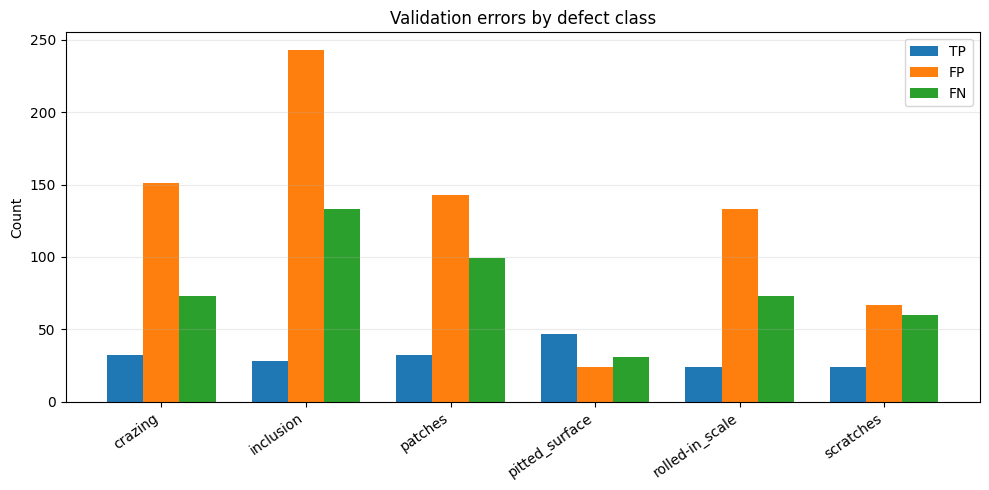

In [6]:

class_rows=[]
for cls_id,cls_name in enumerate(CLASS_NAMES):
    tp=int(((error_df.status=="TP")&(error_df.predicted_class_id==cls_id)).sum())
    fp=int(((error_df.status=="FP")&(error_df.predicted_class_id==cls_id)).sum())
    fn=int(((error_df.status=="FN")&(error_df.ground_truth_class_id==cls_id)).sum())
    precision=tp/(tp+fp+1e-9)
    recall=tp/(tp+fn+1e-9)
    f1=2*precision*recall/(precision+recall+1e-9)
    class_rows.append({"class":cls_name,"TP":tp,"FP":fp,"FN":fn,
                       "precision":precision,"recall":recall,"f1":f1})
class_error_df=pd.DataFrame(class_rows)
display(class_error_df.round(4))

fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(NUM_CLASSES); width=.25
ax.bar(x-width,class_error_df["TP"],width,label="TP")
ax.bar(x,class_error_df["FP"],width,label="FP")
ax.bar(x+width,class_error_df["FN"],width,label="FN")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES,rotation=35,ha="right")
ax.set_ylabel("Count"); ax.set_title("Validation errors by defect class")
ax.legend(); ax.grid(axis="y",alpha=.25); plt.tight_layout(); plt.show()


## 6. Ground-truth box and anchor-shape analysis

width                             height                       \
                count   mean median    min    max  count   mean median    min   
class                                                                           
crazing           105  0.607  0.630  0.155  0.985    105  0.363  0.340  0.160   
inclusion         161  0.143  0.125  0.050  0.675    161  0.395  0.300  0.060   
patches           131  0.286  0.265  0.085  0.550    131  0.439  0.370  0.075   
pitted_surface     78  0.582  0.547  0.115  0.995     78  0.808  0.955  0.095   
rolled-in_scale    97  0.328  0.325  0.110  0.700     97  0.392  0.355  0.105   
scratches          84  0.165  0.090  0.045  0.990     84  0.684  0.775  0.050   

                        area                             aspect_ratio         \
                   max count   mean median    min    max        count   mean   
class                                                                          
crazing          0.750   105  0.216  0.198  0.071  0.537          105  1.893   
inclusion        0.995   161  0.067  0.038  0.007  0.390          161  0.503   
patches          0.995   131  0.139  0.096  0.010  0.468          131  0.814   
pitted_surface   0.995    78  0.503  0.435  0.022  0.990           78  0.803   
rolled-in_scale  0.905    97  0.133  0.116  0.015  0.384           97  1.028   
scratches        0.995    84  0.083  0.070  0.003  0.458           84  0.755   

                                       
                median    min     max  
class                                  
crazing          1.707  0.207   4.178  
inclusion        0.390  0.150   5.400  
patches          0.724  0.218   2.543  
pitted_surface   0.698  0.222   2.542  
rolled-in_scale  0.881  0.283   2.833  
scratches        0.145  0.056  11.000

Validation GT boxes: 656
Best anchor IoU mean: 0.5836245891376876
Best anchor IoU median: 0.5887276232242584
Best anchor IoU below 0.25: 0.036585365853658534
Best anchor IoU below 0.50: 0.31859756097560976


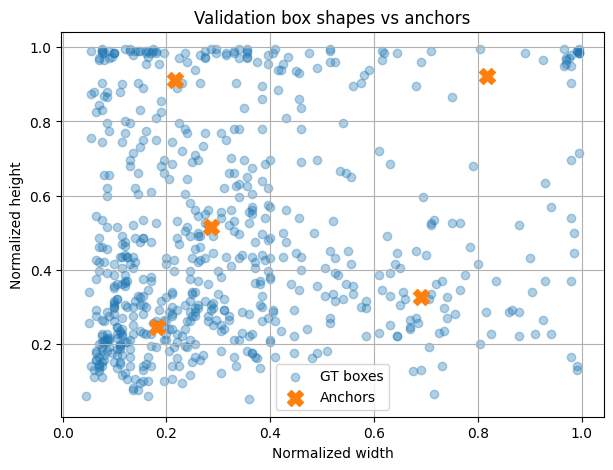

In [7]:

gt_rows=[]
for sample in val_samples:
    boxes,labels=get_gt(sample)
    for box,cls in zip(boxes,labels):
        w=float(box[2]-box[0]); h=float(box[3]-box[1])
        gt_rows.append({"class":CLASS_NAMES[int(cls)],"width":w,"height":h,
                        "area":w*h,"aspect_ratio":w/(h+1e-9)})
gt_df=pd.DataFrame(gt_rows)
display(gt_df.groupby("class")[["width","height","area","aspect_ratio"]].agg(["count","mean","median","min","max"]).round(3))

# Shape-only anchor IoU, ignoring object position.
def wh_iou(wh, anchors_arr):
    inter=np.minimum(wh[0],anchors_arr[:,0])*np.minimum(wh[1],anchors_arr[:,1])
    area=wh[0]*wh[1]
    anchor_area=anchors_arr[:,0]*anchors_arr[:,1]
    return inter/(area+anchor_area-inter+1e-9)

best_ious=[]
for row in gt_rows:
    best_ious.append(float(np.max(wh_iou((row["width"],row["height"]),anchors))))
print("Validation GT boxes:",len(best_ious))
print("Best anchor IoU mean:",np.mean(best_ious))
print("Best anchor IoU median:",np.median(best_ious))
print("Best anchor IoU below 0.25:",np.mean(np.asarray(best_ious)<0.25))
print("Best anchor IoU below 0.50:",np.mean(np.asarray(best_ious)<0.50))

plt.figure(figsize=(7,5))
plt.scatter(gt_df["width"],gt_df["height"],alpha=.35,label="GT boxes")
plt.scatter(anchors[:,0],anchors[:,1],marker="X",s=130,label="Anchors")
plt.xlabel("Normalized width"); plt.ylabel("Normalized height")
plt.title("Validation box shapes vs anchors")
plt.grid(True); plt.legend(); plt.show()


## 7. Inspect images with the most false positives and false negatives

status,image_index,image,FN,FP,TP
45,45,d:\Industrial Surface Defect Detection and Cla...,0,22,0
55,55,d:\Industrial Surface Defect Detection and Cla...,0,17,0
44,44,d:\Industrial Surface Defect Detection and Cla...,0,16,1
250,250,d:\Industrial Surface Defect Detection and Cla...,0,14,0
166,166,d:\Industrial Surface Defect Detection and Cla...,0,13,1
207,207,d:\Industrial Surface Defect Detection and Cla...,0,13,0
270,270,d:\Industrial Surface Defect Detection and Cla...,0,13,1
88,88,d:\Industrial Surface Defect Detection and Cla...,0,9,0
160,160,d:\Industrial Surface Defect Detection and Cla...,0,9,2
209,209,d:\Industrial Surface Defect Detection and Cla...,0,9,0


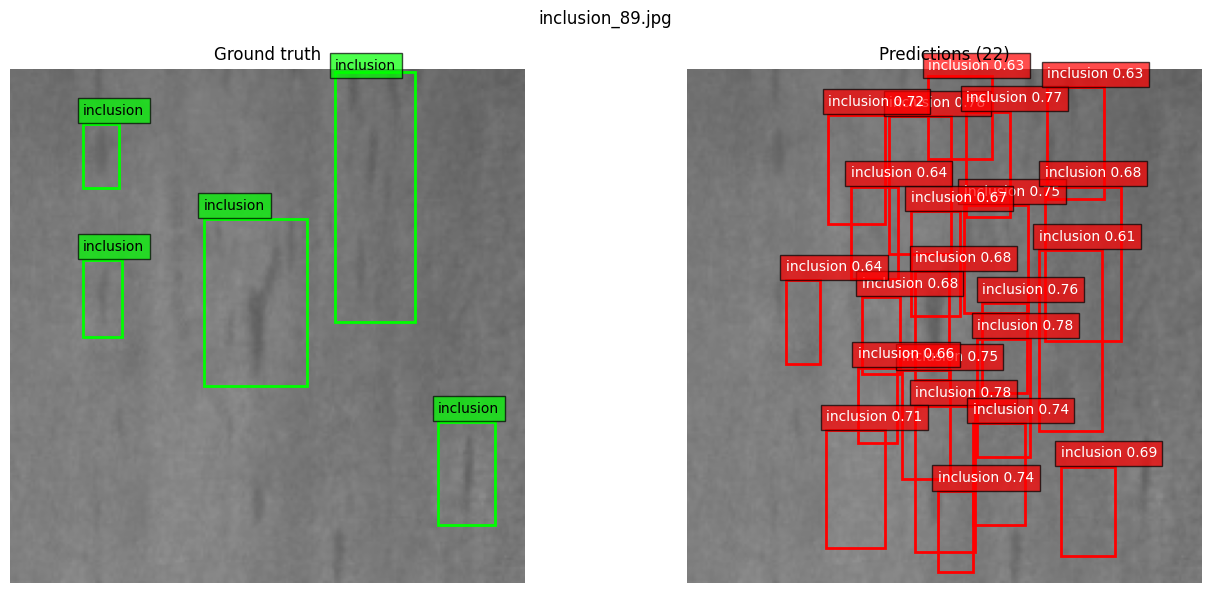

In [8]:

counts=error_df.pivot_table(index=["image_index","image"],columns="status",
                            values="score",aggfunc="count",fill_value=0).reset_index()
for col in ["TP","FP","FN"]:
    if col not in counts: counts[col]=0
counts=counts.sort_values(["FP","FN"],ascending=False)
display(counts.head(15))

def show_error_image(image_index):
    sample=val_samples[int(image_index)]
    image=load_image(sample["image"])
    # Inverse MobileNetV2 preprocessing for display only.
    display_image=(image+1.0)/2.0
    gt_boxes,gt_labels=get_gt(sample)
    dets=validation_predictions[int(image_index)]
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    axes[0].imshow(np.clip(display_image,0,1))
    for box,cls in zip(gt_boxes,gt_labels):
        x1,y1,x2,y2=box
        axes[0].add_patch(plt.Rectangle((x1*IMAGE_SIZE,y1*IMAGE_SIZE),
                         (x2-x1)*IMAGE_SIZE,(y2-y1)*IMAGE_SIZE,
                         fill=False,edgecolor="lime",linewidth=2))
        axes[0].text(x1*IMAGE_SIZE,max(0,y1*IMAGE_SIZE-4),CLASS_NAMES[int(cls)],
                     color="black",bbox=dict(facecolor="lime",alpha=.7))
    axes[0].set_title("Ground truth"); axes[0].axis("off")
    axes[1].imshow(np.clip(display_image,0,1))
    for det in dets:
        x1,y1,x2,y2=det["box"]; cls=det["class_id"]
        axes[1].add_patch(plt.Rectangle((x1*IMAGE_SIZE,y1*IMAGE_SIZE),
                         (x2-x1)*IMAGE_SIZE,(y2-y1)*IMAGE_SIZE,
                         fill=False,edgecolor="red",linewidth=2))
        axes[1].text(x1*IMAGE_SIZE,max(0,y1*IMAGE_SIZE-4),
                     f"{CLASS_NAMES[cls]} {det['score']:.2f}",
                     color="white",bbox=dict(facecolor="red",alpha=.7))
    axes[1].set_title(f"Predictions ({len(dets)})"); axes[1].axis("off")
    plt.suptitle(Path(sample["image"]).name); plt.tight_layout(); plt.show()

# Inspect the highest-error validation image.
if len(counts):
    show_error_image(int(counts.iloc[0]["image_index"]))


## 8. Save diagnostic outputs

In [9]:

raw_stats_path=RESULTS_DIR/f"{MODEL_NAME.lower()}_raw_validation_diagnostics.csv"
errors_path=RESULTS_DIR/f"{MODEL_NAME.lower()}_validation_error_records.csv"
class_path=RESULTS_DIR/f"{MODEL_NAME.lower()}_validation_class_error_summary.csv"
gt_path=RESULTS_DIR/"validation_ground_truth_box_analysis.csv"

raw_stats_df.to_csv(raw_stats_path,index=False)
error_df.to_csv(errors_path,index=False)
class_error_df.to_csv(class_path,index=False)
gt_df.to_csv(gt_path,index=False)

print("Saved:")
for path in [raw_stats_path,errors_path,class_path,gt_path]:
    print(path)


Saved:
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\focal_loss_raw_validation_diagnostics.csv
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\focal_loss_validation_error_records.csv
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\focal_loss_validation_class_error_summary.csv
d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\validation_ground_truth_box_analysis.csv


## 9. How to use these findings

Do not automatically change the model based on one metric.

Use the diagnostic outputs to decide the next experiment:

- **Many FPs across classes:** inspect objectness calibration, negative-objectness weighting, and NMS behavior.
- **Many FNs with low scores:** inspect positive-objectness learning and class confidence; do not just lower the threshold without comparing validation precision/recall.
- **Poor box overlap:** inspect target encoding/decoding consistency, anchor assignment, and box regression loss.
- **One or two weak classes:** inspect class-wise sample counts, label mapping, and augmentation.
- **Poor anchor-shape coverage:** consider recomputing anchors from training boxes only, then retrain and re-evaluate.

The notebook is diagnostic only. It does not modify checkpoints, and it does not use the test split. Share the per-class summary, anchor coverage statistics, and the highest-error image output before choosing the next training change.